# Imports

In [11]:
#%pip install pandas
#%pip install openpyxl

In [16]:
#%pip install seaborn 
%pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------- ----------------------------- 9.4/37.4 MB 51.4 MB/s eta 0:00:01
   ----------------------- ---------------- 21.5/37.4 MB 56.0 MB/s eta 0:00:01
   ------------------------------------- -- 34.6/37.4 MB 56.9 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 47.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import pandas as pd
import seaborn as sns
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt



In [29]:
df = pd.read_csv('../dados/base_quedas_AACD_anonimizada.csv')
df.head()

,ID,Sexo,Idade,Clínica/Dx,Diagnóstico Funcional,Polifarmácia,Suporte social (terapêutico),Suporte social (domiciliar),Status funcional,Cognição (MOCA),...,Braço D,Braço E,10 metros,Aditamento 10m,CIF equilíbrio,Posição equilíbrio,Reação (blazepod),Reação (blazepod) DT,Custo dupla tarefa,Velocidade (m/s)
0,1,M,68,LEA - Lesão Encefálica Adquirida,Hemiparesia,não,esposa e filhos,esposa e filhos,marcha domiciliar com supervisão,NaN,...,NaN,NaN,53.0,Bastão de caminhada,0.0,Sentado,11.0,NaN,NaN,0.188679
1,2,M,72,AMP - Amputação,não informado,não,amigo,não informado,não informado,20.0,...,NaN,NaN,10.0,Muletas axilares,0.0,Sentado,40.0,18.0,NaN,1.000000
2,3,F,77,Parkinson,não informado,não,cuidadora,marido,não informado,20.0,...,NaN,NaN,NaN,NaN,0.0,Sentado,39.0,31.0,NaN,NaN
3,4,M,62,AMP - Amputação,não informado,não,não informado,não informado,não informado,NaN,...,NaN,NaN,7.0,Muleta canadense unilateral,0.0,Ortostatismo,33.0,19.0,NaN,1.428571
4,5,F,62,DNM - Doença Neuromuscular,não informado,não,não informado,não informado,deambuladora comunitária independente,NaN,...,NaN,NaN,7.0,nenhum,0.0,Ortostatismo,33.0,19.0,NaN,1.428571


### Fazendo gráfico que rensponde peguntas importante para o projeto 

* Quantos pacientes estão caindo, e com que frequência?


                        Tipo	|Significado
                    Frequência absoluta	|  Quantidade de vezes que algo aconteceu.
                    Frequência relativa	|  Porcentagem que essa quantidade representa em relação ao total.

In [36]:
# Contar a quantidade de quedas
total_quedas = df['Nº quedas ao chão'].sum()

# Contar a quantidade de pacientes
total_pacientes = len(df)

print("Total de quedas:", total_quedas)
print("Total de pacientes:", total_pacientes)

# Frequência absoluta
frequencia_absoluta = df['Nº quedas ao chão'].value_counts().sort_index()

# Frequência relativa
frequencia_relativa = (
    df['Nº quedas ao chão'].value_counts(normalize=True).sort_index() * 100
)

# Criar tabela organizada
tabela_frequencia = pd.DataFrame({
    'Frequência absoluta': frequencia_absoluta,
    'Frequência relativa (%)': frequencia_relativa
})

display(tabela_frequencia.round(2))

# Considerar somente pacientes com informação válida
dados_validos = df['Nº quedas ao chão'].dropna()

# Quantidade de pacientes que sofreram quedas
pacientes_com_quedas = (dados_validos > 0).sum()

# Total de pacientes com informação válida
total_validos = len(dados_validos)

# Frequência percentual
frequencia = (pacientes_com_quedas / total_validos) * 100

print(f"Pacientes que caíram: {pacientes_com_quedas}")
print(f"Pacientes com dados válidos: {total_validos}")
print(f"Porcentagem de pacientes que caíram: {frequencia:.2f}%")

Total de quedas: 364.0
Total de pacientes: 282


,Frequência absoluta,Frequência relativa (%)
Nº quedas ao chão,,
0.0,128,46.72
1.0,68,24.82
2.0,32,11.68
3.0,19,6.93
4.0,9,3.28
5.0,9,3.28
6.0,3,1.09
10.0,4,1.46
16.0,1,0.36


Pacientes que caíram: 146
Pacientes com dados válidos: 274
Porcentagem de pacientes que caíram: 53.28%


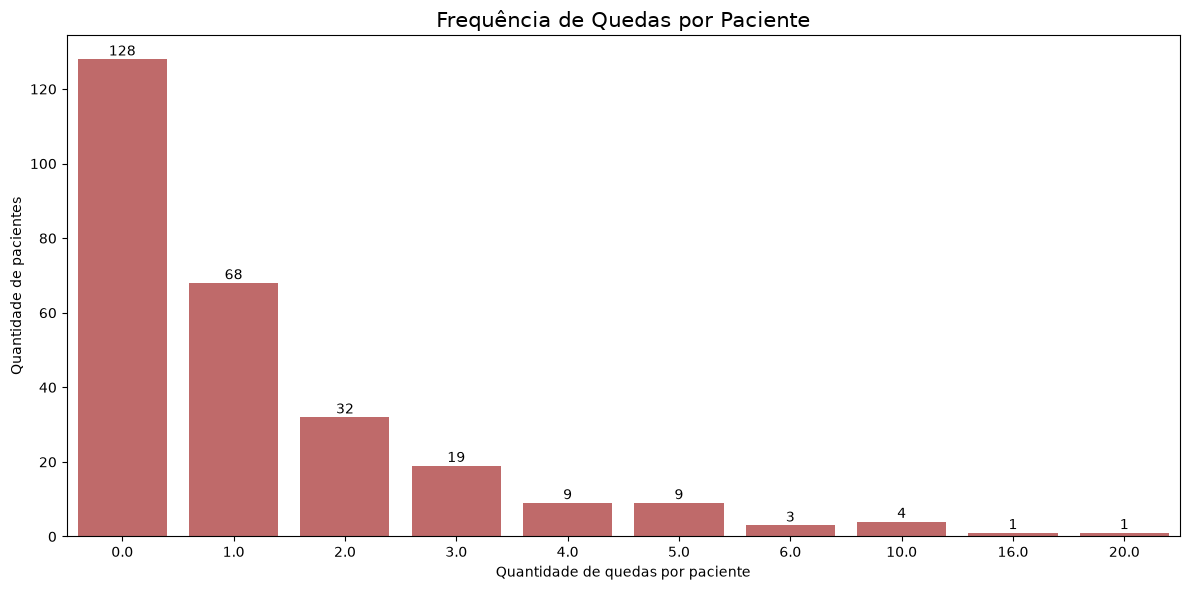

In [41]:


# Remover valores ausentes
dados_validos = df['Nº quedas ao chão'].dropna()

# Contar quantos pacientes tiveram cada quantidade de quedas
frequencia = dados_validos.value_counts().sort_index()

# Criar gráfico
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=frequencia.index,
    y=frequencia.values,
    color='indianred'
)

# Adicionar valores em cima das barras
for i, valor in enumerate(frequencia.values):
    ax.text(i, valor + 1, str(valor),
            ha='center', fontsize=10)

# Personalização
plt.title('Frequência de Quedas por Paciente',
          fontsize=15)

plt.xlabel('Quantidade de quedas por paciente')
plt.ylabel('Quantidade de pacientes')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

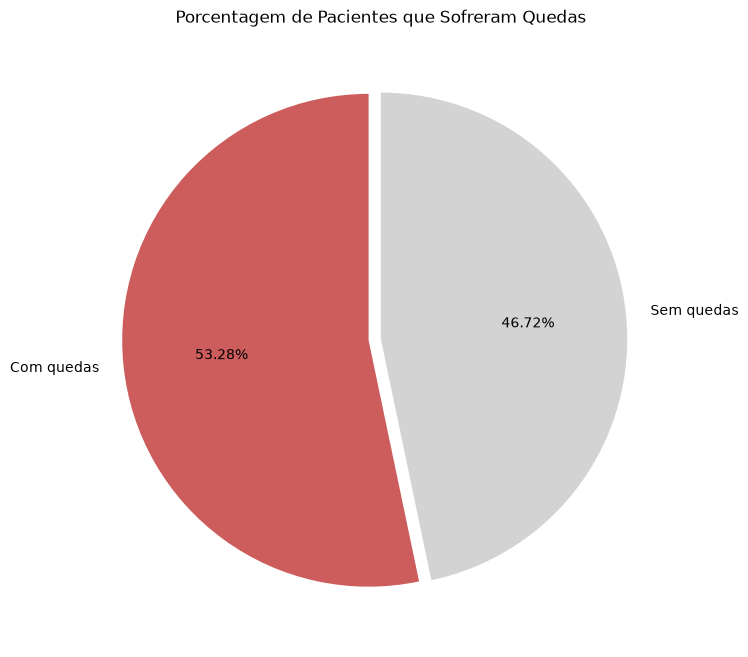

In [ ]:

# Contar pacientes com e sem quedas
dados = df['Nº quedas ao chão'].dropna()

com_quedas = (dados > 0).sum()
sem_quedas = (dados == 0).sum()

# Criar gráfico de pizza
plt.figure(figsize=(8, 8))

plt.pie(
    [com_quedas, sem_quedas],
    labels=['Com quedas', 'Sem quedas'],
    autopct='%1.2f%%',
    startangle=90,
    explode=(0.05, 0),
    colors=['indianred', 'lightgray']
)

plt.title('Porcentagem de Pacientes que Sofreram Quedas')
plt.show()